# COVID-19 Case Trends, Policy Response & Short-Term Forecasting

Two questions, using ECDC weekly COVID-19 data (2020-2022) and a government policy-measures dataset:

1. **Descriptively:** how did case/death trends and government measures evolve together?
2. **Predictively:** can recent case history plus active policy measures forecast next week's cases - both whether they rise or fall and by how much?

**Notebook outline**

1. Load data
2. Descriptive plots
3. Build the modelling dataset
4. MLP with historical case and death features
5. Raw one-headed LSTM direct regression
6. Two-headed LSTM direction and magnitude model
7. Model comparison and per-country forecast plots

**Cleaning decisions**

- The weekly ECDC file contains both `cases` and `deaths` rows; cases are the target and deaths are an historical predictor.
- The MLP uses four lagged case-rate features and previous-week deaths.
- Both LSTMs use historical case/death rates and policy sequences without using the target week's case value as an input.
- All predictive evaluation is chronological: training weeks precede validation weeks, and validation weeks precede the final test period.
- The raw one-headed LSTM is the simple direct-regression baseline. The two-headed LSTM is the more specialized direction-plus-magnitude model.

> Run all cells from top to bottom. The LSTM cells train several seeds and may take several minutes on CPU.


In [1]:
# Reduce TensorFlow's startup logging so notebook output stays focused.
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score, f1_score

import tensorflow as tf
from tensorflow.keras import layers, models

DATA_DIR = "Data"
CASES_FILE = f"{DATA_DIR}/data_new.csv"
POLICY_FILE = f"{DATA_DIR}/response_graphs_data_2022-08-25.csv"

MODEL_COUNTRIES = ["Belgium", "Bulgaria", "Croatia", "Czechia", "Hungary", "Ireland",
                   "Malta", "Poland", "Romania", "Slovakia", "Cyprus"]

# All predictive models use a chronological split at this date.
CUTOFF = pd.Timestamp("2021-09-01")
LOOKBACK = 12
BATCH_SIZE, EPOCHS = 32, 40
PATIENCE, MIN_DELTA = 8, 1e-4
SEEDS = [0, 1, 2, 3, 4]
SEED = 42
PER_CAPITA_SCALE = 100_000.0
DELTA_HUBER, LAMBDA_MAG = 0.2, 0.05
METRICS = ["direction_accuracy", "direction_auc", "direction_f1",
           "MAE_per_100k", "median_error_per_100k"]

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", None)

## 1. Load data

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

CASES_URL = "https://opendata.ecdc.europa.eu/covid19/nationalcasedeath_archive/csv/data.csv"
POLICY_URL = "https://www.ecdc.europa.eu/sites/default/files/documents/response_graphs_data_2022-08-25.csv"


def download_if_missing(url, destination):
    """Download an input file once, then reuse the local cached copy."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        print(f"Using cached {destination}")
        return

    temporary = destination.with_suffix(destination.suffix + ".part")
    print(f"Downloading {url}")
    urlretrieve(url, temporary)
    temporary.replace(destination)
    print(f"Saved {destination}")


# These URLs are the official archived ECDC downloads verified on 2026-10-12.
download_if_missing(CASES_URL, CASES_FILE)
download_if_missing(POLICY_URL, POLICY_FILE)

# Load the weekly ECDC file. It contains a separate row for each
# country-week-indicator combination, so both cases and deaths are present.
cases_raw = pd.read_csv(CASES_FILE)

# Convert the ISO year-week label (for example, "2020-07") into the Monday
# that starts that ISO week. Using a real datetime makes sorting, filtering,
# plotting, and time-based splitting reliable.
yw = cases_raw["year_week"].str.split("-", expand=True).astype(int)
cases_raw["date"] = pd.to_datetime(
    [datetime.date.fromisocalendar(y, w, 1) for y, w in zip(yw[0], yw[1])]
)

# Load policy intervals. Invalid date strings become NaT so they can be
# removed explicitly during the modelling-data construction step.
policy_raw = pd.read_csv(POLICY_FILE)
for col in ["date_start", "date_end"]:
    policy_raw[col] = pd.to_datetime(policy_raw[col], errors="coerce")

# Basic inventory checks make it immediately visible whether the expected
# indicators and policy vocabulary were loaded successfully.
print("Case file:  ", cases_raw.shape, "| indicators:", sorted(cases_raw["indicator"].unique()))
print("Policy file:", policy_raw.shape, "| measures:", policy_raw["Response_measure"].nunique())

Using cached Data\data_new.csv
Using cached Data\response_graphs_data_2022-08-25.csv
Case file:   (53074, 12) | indicators: ['cases', 'deaths']
Policy file: (2021, 4) | measures: 66


## 2. Descriptive plots

These plots are for looking at the data, not for measuring anything. They show the periods during which measures were in force next to the case and death curves. 

In [3]:
"""Create descriptive plots for policy intervals and case/death time series."""


def plot_country_measures(df, country,
                          figsize=(12,6), linewidth=6, cmap='tab20',
                          date_fmt='%Y-%m-%d', right_space=0.75):
    """Plot every recorded policy interval for one country.

    Each response measure receives its own horizontal y-position. A thick line
    from ``date_start`` to ``date_end`` shows when that measure was recorded as
    active. The function returns the figure and axis so callers can customise
    or save the plot.
    """
    # Work on a copy so plotting never mutates the caller's DataFrame.
    country_data = df[df['Country'] == country].copy()
    if country_data.empty:
        raise ValueError(f"No rows for country: {country}")

    # Assign a stable vertical position and colour to each distinct measure.
    measures = country_data['Response_measure'].unique()
    measure_to_y = {m: i for i, m in enumerate(measures)}
    fig, ax = plt.subplots(figsize=(figsize[0], max(figsize[1], len(measures)*0.35)))
    cmap_obj = plt.get_cmap(cmap)
    colors = [cmap_obj(i % cmap_obj.N) for i in range(len(measures))]

    # Draw one interval per policy record.
    for _, row in country_data.iterrows():
        y = measure_to_y[row['Response_measure']]
        ax.hlines(y, row['date_start'], row['date_end'],
                  linewidth=linewidth, color=colors[y], alpha=0.95)

    # Turn the numeric y positions back into human-readable policy names.
    ax.set_yticks(list(measure_to_y.values()))
    ax.set_yticklabels(list(measure_to_y.keys()), fontsize='small')
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter(date_fmt))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize='small')
    ax.set_xlabel('Date')
    ax.set_ylabel('Measures')
    ax.set_title(f'COVID-19 Response Measures in {country}')
    plt.tight_layout()
    plt.subplots_adjust(right=right_space)
    return fig, ax


"""Plot cases, deaths, and selected policy intervals for one country.

The plot is descriptive only. Shaded intervals show overlap in calendar time;
this does not estimate a lag or establish a causal effect.
"""


def plot_cases_with_measures(data, response_data, country,
                             selected_measures,
                             country_col='country', date_col='date',
                             cases_col='cases', deaths_col='deaths',
                             value_col='weekly_count',
                             figsize=(12,5), cmap='tab20',
                             alpha_span=0.25, alpha_patch=0.6,
                             date_fmt='%Y-%m-%d', right_space=0.25,
                             aggregate='sum',
                             share_y_scale=False):
    # Copy both inputs because dates are normalised locally for plotting.
    df = data.copy()
    resp = response_data.copy()
    df[date_col] = pd.to_datetime(df[date_col])
    resp['date_start'] = pd.to_datetime(resp['date_start'])
    resp['date_end'] = pd.to_datetime(resp['date_end'])

    # Restrict the case/death data to one country before reshaping it.
    s = df[df[country_col] == country].copy()
    if s.empty:
        raise ValueError(f"No rows for country: {country} in data[{country_col}]")

    # The source has one row per indicator. Pivoting creates separate cases and
    # deaths columns while aggregating any accidental duplicate date rows.
    if 'indicator' in s.columns:
        pivot = s.pivot_table(index=date_col, columns='indicator', values=value_col, aggfunc=aggregate).reset_index()
        pivot.columns.name = None
        if 'cases' in pivot.columns:
            pivot = pivot.rename(columns={'cases': cases_col})
        if 'deaths' in pivot.columns:
            pivot = pivot.rename(columns={'deaths': deaths_col})
        series = pivot.sort_values(by=date_col)
    else:
        series = s.sort_values(by=date_col)

    # Guarantee one plotted point per date even when the input has duplicates.
    if series.duplicated(subset=[date_col]).any():
        series = series.groupby(date_col, as_index=False).agg({col: 'sum' for col in series.columns if col != date_col})

    measures = resp[resp['Country'] == country].copy()

    # Cases use the primary axis; deaths use a secondary axis because their
    # scale is usually much smaller than the case count.
    fig, ax = plt.subplots(figsize=figsize)
    if cases_col in series.columns:
        ax.plot(series[date_col], series[cases_col], ".-r", label='cases')
    else:
        ax.plot([], [], ".-r", label='cases (missing)')
    ax2 = None
    if deaths_col in series.columns:
        ax2 = ax.twinx()
        ax2.plot(series[date_col], series[deaths_col], ".-k", label='deaths')
        ax2.set_ylabel(deaths_col, color='k')
        for tl in ax2.get_yticklabels():
            tl.set_color('k')
    else:
        ax.plot([], [], ".-k", label='deaths (missing)')

    # Sharing limits is optional: it helps visual comparison but can make the
    # smaller death series visually difficult to inspect.
    if share_y_scale and ax2 is not None:
        ax2.set_ylim(ax.get_ylim())

    # Shade only the requested measures and build matching legend patches.
    if not measures.empty:
        measures = measures[measures['Response_measure'].isin(selected_measures)]
        if measures.empty:
            raise ValueError("None of the selected_measures found for this country")
        cmap_obj = plt.get_cmap(cmap)
        unique_measures = measures['Response_measure'].unique()
        color_map = {m: cmap_obj(i % cmap_obj.N) for i, m in enumerate(unique_measures)}
        for _, row in measures.iterrows():
            ax.axvspan(row['date_start'], row['date_end'],
                       color=color_map[row['Response_measure']], alpha=alpha_span)
        patch_handles = [Patch(facecolor=color_map[m], alpha=alpha_patch, label=m) for m in unique_measures]
    else:
        patch_handles = []

    # Combine handles from both axes and the shaded policy intervals into one
    # figure-level legend.
    handles, labels = ax.get_legend_handles_labels()
    if ax2 is not None:
        h2, l2 = ax2.get_legend_handles_labels()
        handles += h2; labels += l2
    handles += patch_handles

    fig.legend(handles=handles,
               bbox_to_anchor=(1.02, 0.95),
               loc='upper left',
               fontsize='small',
               bbox_transform=fig.transFigure)
    right_margin = max(0.55, min(right_space, 0.9))
    fig.subplots_adjust(right=right_margin)
    if ax2 is not None:
        try:
            # Keep the secondary axis at the right edge of the plotting area.
            ax2.spines['right'].set_position(('axes', 1.0))
            ax2.yaxis.set_label_position('right')
            ax2.yaxis.set_ticks_position('right')
            for tl in ax2.get_yticklabels():
                tl.set_color('k')
        except Exception:
            # Axis styling should never prevent the descriptive plot from being
            # produced if a backend does not support this positioning call.
            pass

    ax.set_xlabel('Date')
    ax.set_ylabel(cases_col, color='r')
    for tl in ax.get_yticklabels():
        tl.set_color('r')
    ax.set_title(f"{value_col} in {country} with selected measures")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter(date_fmt))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()
    return fig, ax

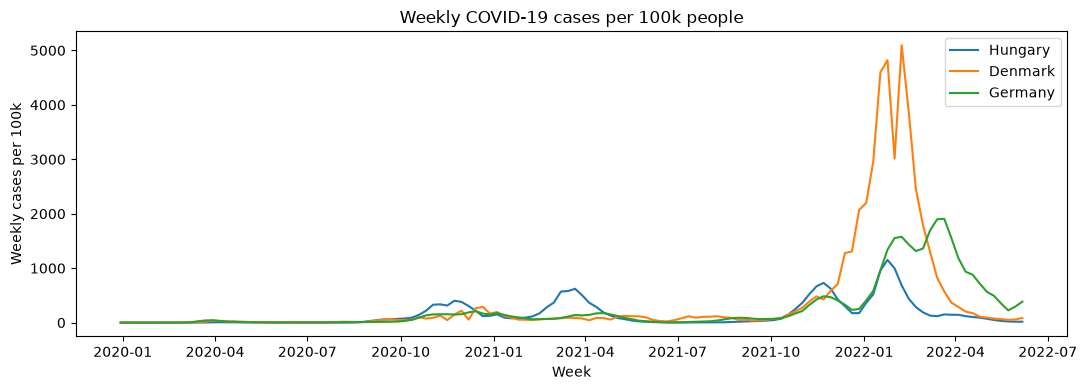

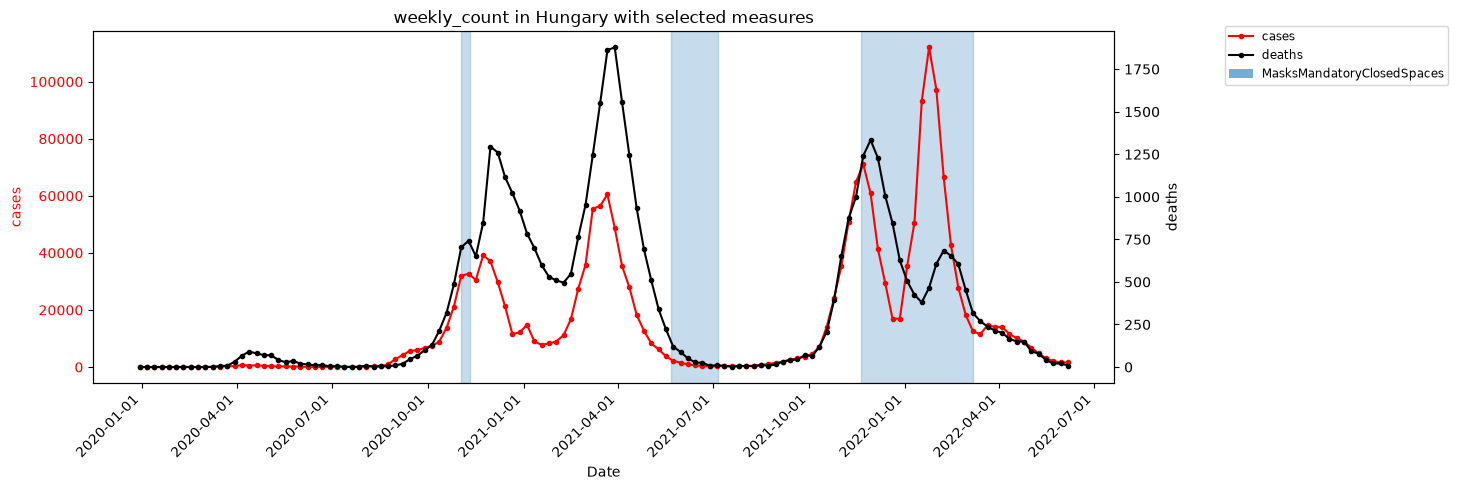

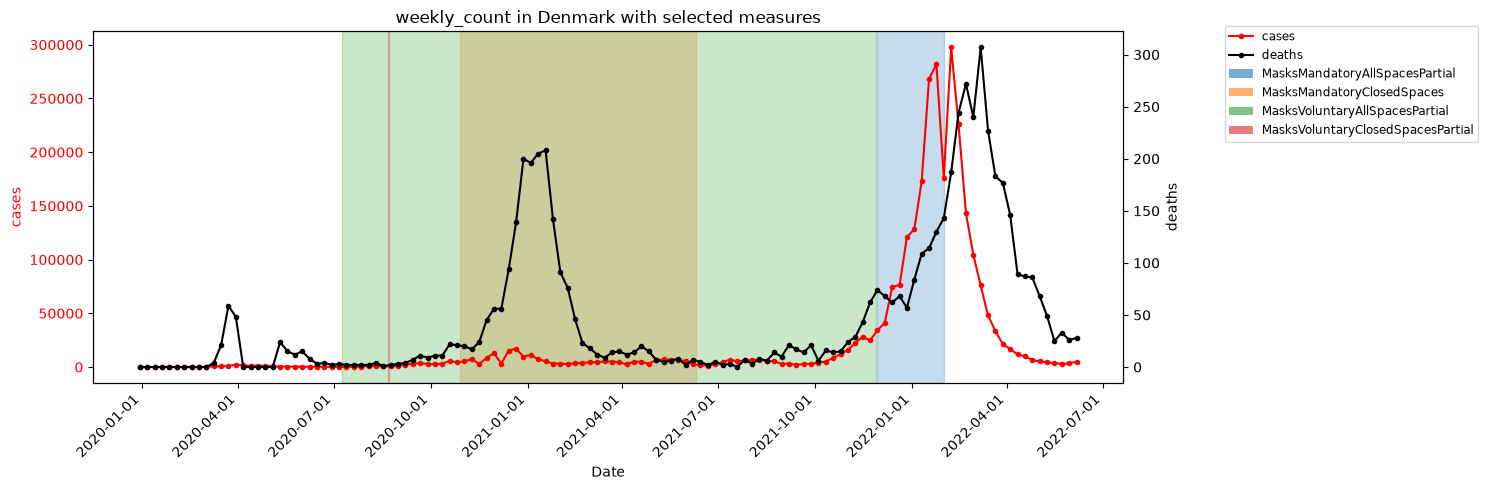

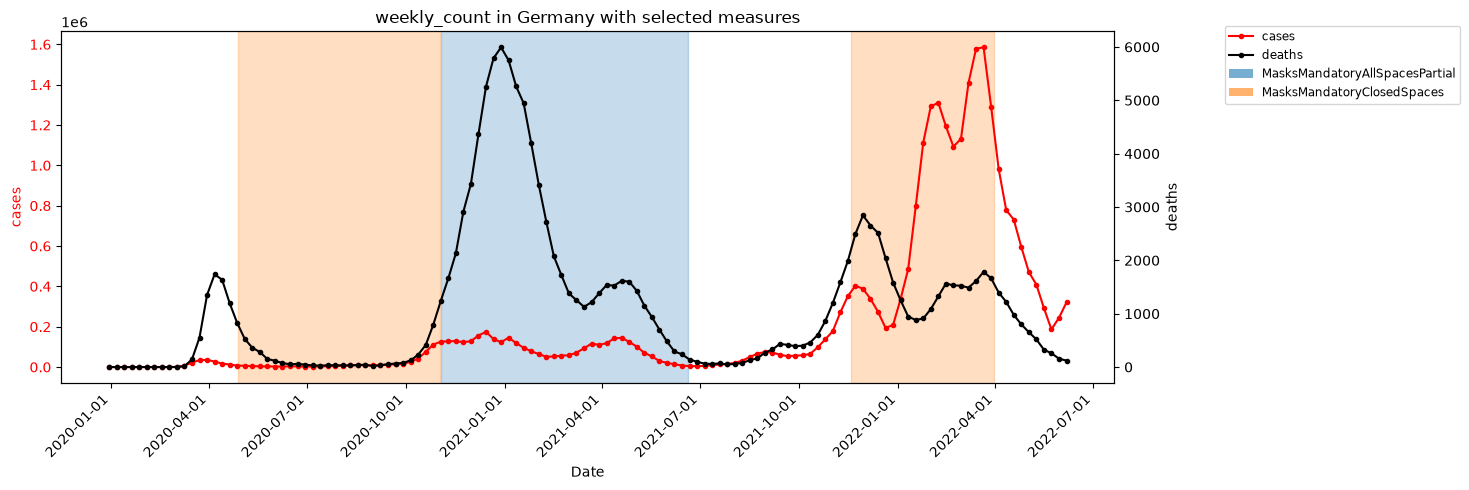

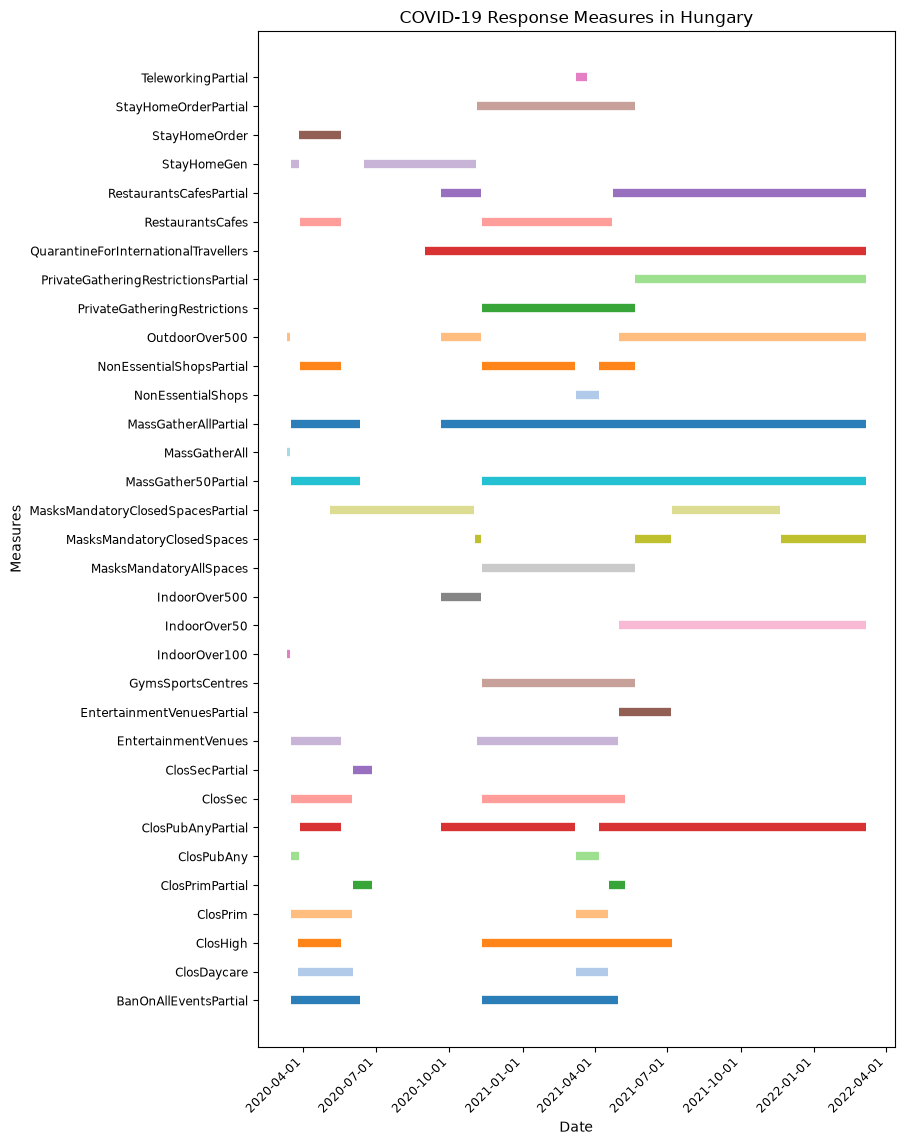

In [4]:
# Countries used in the small descriptive example set.
EXAMPLE_COUNTRIES = ["Hungary", "Denmark", "Germany"]

# Plot weekly case rates rather than raw counts so countries can be compared
# despite having different population sizes.
fig, ax = plt.subplots(figsize=(11, 4))
for c in EXAMPLE_COUNTRIES:
    # Keep only the cases indicator; the source file also contains deaths.
    s = cases_raw[(cases_raw["country"] == c) & (cases_raw["indicator"] == "cases")].sort_values("date")
    if s.empty:
        # Missing countries should not stop the remaining examples from plotting.
        continue
    ax.plot(s["date"], s["weekly_count"] / s["population"] * PER_CAPITA_SCALE, label=c)
ax.set_xlabel("Week")
ax.set_ylabel("Weekly cases per 100k")
ax.set_title("Weekly COVID-19 cases per 100k people")
ax.legend()
plt.tight_layout()
plt.show()

# Overlay selected mask-policy intervals on the case/death curves. This is a
# visual comparison of timing, not a causal analysis.
MASK_MEASURES = ["MasksMandatoryAllSpacesPartial", "MasksMandatoryClosedSpaces",
                 "MasksVoluntaryAllSpacesPartial", "MasksVoluntaryClosedSpacesPartial"]
for c in EXAMPLE_COUNTRIES:
    try:
        plot_cases_with_measures(cases_raw, policy_raw, c, MASK_MEASURES, cmap="tab10")
        plt.show()
    except ValueError as e:
        # Report a missing country or measure selection and continue plotting.
        print(f"{c}: {e}")

# Show the complete policy timeline for one country as a second descriptive view.
fig, ax = plot_country_measures(policy_raw, "Hungary")
plt.show()

## 3. Build the modelling dataset

Steps: keep **cases as the target** and **deaths as an optional historical feature** -> fix policy date ranges -> keep countries present in both files -> expand each measure into weekly on/off columns -> merge. A week with no recorded measure means no measure was active, so those entries are `0`. Missing deaths are tracked explicitly with a `deaths_missing` indicator instead of being silently converted to zero, because a missing death count is not the same as a real zero.


In [16]:
# 1. Pivot cases and deaths into separate columns for each country-week.
# Deaths are retained as a candidate historical predictor, while cases remain
# the forecasting target used by every model.
indicator_data = (cases_raw[cases_raw["indicator"].isin(["cases", "deaths"])]
                  .rename(columns={"country": "Country", "date": "week"})
                  [["Country", "week", "indicator", "weekly_count", "population"]]
                  .pivot_table(index=["Country", "week", "population"],
                               columns="indicator", values="weekly_count", aggfunc="sum")
                  .reset_index())
indicator_data.columns.name = None
indicator_data = indicator_data.rename(columns={
    "cases": "weekly_count",
    "deaths": "deaths_weekly_count",
})
if "deaths_weekly_count" not in indicator_data.columns:
    raise ValueError("The source file does not contain a deaths indicator.")

cases = indicator_data.dropna(subset=["weekly_count", "population"]).copy()
missing_deaths = int(cases["deaths_weekly_count"].isna().sum())
print(f"Deaths missing before modelling: {missing_deaths} rows out of {len(cases)}")
cases["deaths_missing"] = cases["deaths_weekly_count"].isna()
# We explicitly keep the missingness flag rather than silently converting the
# unknown death total to zero, which would make a genuine data gap look like a
# real no-death week.

# 2. Retain policy rows with usable date ranges. A reversed interval is a data
# entry issue, so swap its endpoints instead of silently discarding the row.
policy = policy_raw.dropna(subset=["date_start", "date_end"]).copy()
swapped = policy["date_end"] < policy["date_start"]
policy.loc[swapped, ["date_start", "date_end"]] = policy.loc[swapped, ["date_end", "date_start"]].values
print(f"Policy rows: {len(policy_raw)} -> {len(policy)} after dropping missing dates; {int(swapped.sum())} reversed date ranges fixed")

# 3. A merge is valid only where country names match exactly in both sources.
common = sorted(set(cases["Country"]) & set(policy["Country"]))
policy_only = sorted(set(policy["Country"]) - set(cases["Country"]))
print(f"{len(common)} countries in both files.")
print("In the policy file but NOT in the case file (check for spelling differences):", policy_only)

# 4. Expand every policy interval into the Mon-Sun weeks it overlaps.
# A policy is active for a week if the interval overlaps any day in that calendar week,
# not only if it begins on a Monday. The old W-MON expansion missed intervals that
# started after Monday or lived entirely within a single week.
policy_common = policy[policy["Country"].isin(common)].copy()

legacy_missed = 0
legacy_examples = []
for _, r in policy_common.iterrows():
    start = pd.Timestamp(r["date_start"]).normalize()
    end = pd.Timestamp(r["date_end"]).normalize()
    legacy_weeks = {pd.Timestamp(w).normalize() for w in pd.date_range(start, end, freq="W-MON")}
    overlap_weeks = set()
    monday = start - pd.to_timedelta(start.weekday(), unit="D")
    end_monday = end - pd.to_timedelta(end.weekday(), unit="D")
    current = monday
    while current <= end_monday:
        week_start = current.normalize()
        week_end = (current + pd.Timedelta(days=6)).normalize()
        if start <= week_end and end >= week_start:
            overlap_weeks.add(week_start)
        current += pd.Timedelta(days=7)
    if legacy_weeks != overlap_weeks:
        legacy_missed += 1
        legacy_examples.append((r["Country"], r["Response_measure"], start.date(), end.date(), len(legacy_weeks), len(overlap_weeks)))
print(f"Policy intervals affected by the legacy Monday-only expansion: {legacy_missed} / {len(policy_common)}")
if legacy_examples:
    example = legacy_examples[0]
    print("Example interval missed by old logic:", example[0], example[1], example[2], "->", example[3],
          "(legacy weeks:", example[4], ", overlap weeks:", example[5], ")")

rows = []
for _, r in policy_common.iterrows():
    start = pd.Timestamp(r["date_start"]).normalize()
    end = pd.Timestamp(r["date_end"]).normalize()
    monday = start - pd.to_timedelta(start.weekday(), unit="D")
    end_monday = end - pd.to_timedelta(end.weekday(), unit="D")
    current = monday
    while current <= end_monday:
        week_start = current.normalize()
        week_end = (current + pd.Timedelta(days=6)).normalize()
        if start <= week_end and end >= week_start:
            rows.append((r["Country"], r["Response_measure"], week_start))
        current += pd.Timedelta(days=7)
policy_weekly = pd.DataFrame(rows, columns=["Country", "Response_measure", "week"])

# Pivot the long policy table into one binary feature per response measure.
policy_features = (policy_weekly.assign(active=1)
                   .pivot_table(index=["Country", "week"], columns="Response_measure",
                                values="active", aggfunc="max", fill_value=0)
                   .reset_index())
policy_features.columns.name = None
measure_cols = [c for c in policy_features.columns if c not in ("Country", "week")]

# 5. Left-merge policy features onto every country-week. Missing policy rows
# mean that no measure was recorded for that week, so they are encoded as 0.
final_df = cases[cases["Country"].isin(common)].merge(policy_features, on=["Country", "week"], how="left")
final_df[measure_cols] = final_df[measure_cols].fillna(0)
final_df["deaths_missing"] = final_df["deaths_missing"].fillna(False).astype(bool)
final_df = final_df.dropna(subset=["weekly_count", "population"]).reset_index(drop=True)

n_dup = int(final_df.duplicated(["Country", "week"]).sum())
assert n_dup == 0, f"{n_dup} duplicated (Country, week) rows - check the case file"
print(f"\nfinal_df: {len(final_df)} country-week rows, {final_df['Country'].nunique()} countries, "
      f"{len(measure_cols)} policy measures, weeks {final_df['week'].min().date()} to {final_df['week'].max().date()}")
print("Deaths missing in the modelling dataset:", int(final_df["deaths_missing"].sum()),
      f"of {len(final_df)} rows")


Deaths missing before modelling: 0 rows out of 26537
Policy rows: 2021 -> 1986 after dropping missing dates; 0 reversed date ranges fixed
30 countries in both files.
In the policy file but NOT in the case file (check for spelling differences): []
Policy intervals affected by the legacy Monday-only expansion: 1356 / 1986
Example interval missed by old logic: Austria AdaptationOfWorkplace 2021-04-01 -> 2022-03-05 (legacy weeks: 48 , overlap weeks: 49 )

final_df: 3841 country-week rows, 30 countries, 66 policy measures, weeks 2019-12-30 to 2022-06-13
Deaths missing in the modelling dataset: 0 of 3841 rows


### 4a. First forecasting model: MLP regressor

In [6]:
# The MLP uses contemporaneous policy/population features plus optional historical
# observations. All lagged values are shifted within country before the time split.
def prepare_mlp_frame(final_df, countries=None, history_lags=4):
    df = final_df.copy()
    df["week"] = pd.to_datetime(df["week"], errors="coerce")
    for col in ["weekly_count", "deaths_weekly_count", "population"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Country"] = df["Country"].astype(str)
    if countries is not None:
        df = df[df["Country"].isin(countries)].copy()
    df = (df.dropna(subset=["Country", "week", "weekly_count", "population"])
            .sort_values(["Country", "week"]).reset_index(drop=True))
    df["deaths_weekly_count_lag1"] = df.groupby("Country")["deaths_weekly_count"].shift(1)
    for lag in range(1, history_lags + 1):
        df[f"cases_per_100k_lag{lag}"] = (
            df.groupby("Country")["weekly_count"].shift(lag)
            / df["population"] * PER_CAPITA_SCALE
        )
    return df


def plot_country_value_forecasts(actual_df, prediction_df, value_col, prediction_col, title):
    """Plot actual and predicted values for every country in prediction_df."""
    plot_df = actual_df.merge(prediction_df, on=["Country", "week"], how="left")
    for country, group in plot_df.groupby("Country", sort=True):
        group = group.sort_values("week")
        plt.figure(figsize=(11, 4))
        plt.plot(group["week"], group[value_col], label="Actual")
        plt.plot(group["week"], group[prediction_col], label="Predicted")
        plt.xlabel("Week")
        plt.ylabel(value_col)
        plt.title(f"{country} - {title}")
        plt.legend()
        plt.tight_layout()
        plt.show()


def run_mlp_model(df, cutoff, include_history=False, include_deaths=False):
    """Fit the MLP with chronological validation and per-capita targets."""
    train_df = df[df["week"] < cutoff].copy()
    test_df = df[df["week"] >= cutoff].copy()
    if train_df.empty or test_df.empty:
        raise ValueError("Empty MLP train/test split - check CUTOFF.")

    excluded = {"Country", "week", "weekly_count", "deaths_weekly_count"}
    history_cols = [c for c in df.columns if c.startswith("cases_per_100k_lag")]
    if not include_history:
        excluded.update(history_cols)
    if not include_deaths:
        excluded.add("deaths_weekly_count_lag1")
    feature_cols = [c for c in df.columns if c not in excluded]

    validation_mask = chronological_val_mask(train_df["week"], frac=0.2)
    fit_df = train_df.loc[~validation_mask].copy()
    validation_df = train_df.loc[validation_mask].copy()
    if fit_df.empty or validation_df.empty:
        raise ValueError("Chronological MLP validation split is empty.")

    imputer = SimpleImputer(strategy="median").fit(
        fit_df[feature_cols].apply(pd.to_numeric, errors="coerce")
    )
    scaler = StandardScaler().fit(imputer.transform(
        fit_df[feature_cols].apply(pd.to_numeric, errors="coerce")
    ))

    def transform(frame):
        values = frame[feature_cols].apply(pd.to_numeric, errors="coerce")
        return scaler.transform(imputer.transform(values))

    def target(frame):
        return (frame["weekly_count"] / frame["population"] * PER_CAPITA_SCALE).to_numpy(float)

    X_fit, y_fit = transform(fit_df), target(fit_df)
    y_validation = target(validation_df)
    target_scaler = StandardScaler().fit(y_fit.reshape(-1, 1))
    y_fit_scaled = target_scaler.transform(y_fit.reshape(-1, 1)).ravel()

    iteration_candidates = [400, 800, 1200]
    validation_scores = []
    for max_iter in iteration_candidates:
        candidate = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                                 solver="adam", learning_rate_init=1e-3,
                                 alpha=1e-4, max_iter=max_iter, early_stopping=False,
                                 tol=1e-4, random_state=SEED)
        candidate.fit(X_fit, y_fit_scaled)
        candidate_prediction = target_scaler.inverse_transform(
            candidate.predict(transform(validation_df)).reshape(-1, 1)
        ).ravel()
        validation_scores.append((mean_absolute_error(y_validation, candidate_prediction), max_iter))
    selected_max_iter = min(validation_scores)[1]

    X_train, y_train = transform(train_df), target(train_df)
    X_test, y_test = transform(test_df), target(test_df)
    target_scaler = StandardScaler().fit(y_train.reshape(-1, 1))
    final_mlp = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                             solver="adam", learning_rate_init=1e-3,
                             alpha=1e-4, max_iter=selected_max_iter,
                             early_stopping=False, tol=1e-4, random_state=SEED)
    final_mlp.fit(X_train, target_scaler.transform(y_train.reshape(-1, 1)).ravel())
    prediction = target_scaler.inverse_transform(
        final_mlp.predict(X_test).reshape(-1, 1)
    ).ravel()
    actual_counts = test_df["weekly_count"].to_numpy(float)
    prediction_counts = prediction * test_df["population"].to_numpy(float) / PER_CAPITA_SCALE
    result = test_df[["Country", "week", "weekly_count"]].copy()
    result["predicted_weekly_count"] = prediction_counts
    metrics = {
        "selected_max_iter": int(selected_max_iter),
        "validation_mae_per_100k": float(min(validation_scores)[0]),
        "train_r2": float(final_mlp.score(X_train, target_scaler.transform(y_train.reshape(-1, 1)).ravel())),
        "test_r2": float(1 - np.sum((y_test - prediction) ** 2) / np.sum((y_test - y_test.mean()) ** 2)),
        "MAE_per_100k": float(mean_absolute_error(y_test, prediction)),
        "RMSE_per_100k": float(np.sqrt(mean_squared_error(y_test, prediction))),
        "bias_per_100k": float(np.mean(prediction - y_test)),
        "median_error_per_100k": float(np.median(np.abs(prediction - y_test))),
        "raw_count_mae_removed": float(mean_absolute_error(actual_counts, prediction_counts)),
    }
    return {"imputer": imputer, "scaler": scaler, "target_scaler": target_scaler,
            "mlp": final_mlp, "feature_cols": feature_cols}, result, metrics

In [7]:
def score_rate_forecast(name, predicted_value, meta, persistence_mae=None, probability=None):
    """Score any per-capita forecast with common regression and direction metrics."""
    actual = meta["curr"].to_numpy(float)
    previous = meta["prev"].to_numpy(float)
    predicted_value = np.asarray(predicted_value, dtype=float)
    predicted_direction = ((probability >= 0.5) if probability is not None
                           else (predicted_value > previous)).astype(float)
    actual_direction = (actual > previous).astype(float)
    errors = np.abs(predicted_value - actual)
    try:
        direction_auc = float(roc_auc_score(actual_direction, probability if probability is not None else predicted_value))
    except ValueError:
        direction_auc = np.nan
    mae = float(errors.mean())
    return {
        "model": name,
        "direction_accuracy": float(np.mean(predicted_direction == actual_direction)),
        "direction_auc": direction_auc,
        "direction_f1": float(f1_score(actual_direction, predicted_direction, zero_division=0)),
        "MAE_per_100k": mae,
        "median_error_per_100k": float(np.median(errors)),
        "bias_per_100k": float(np.mean(predicted_value - actual)),
        "MAE_relative_to_persistence": float(mae / persistence_mae) if persistence_mae else np.nan,
    }


def make_baseline_predictions(full_df, target_meta, cutoff):
    """Create persistence, rolling-mean, and fixed-alpha lagged ridge forecasts."""
    full_df = full_df.sort_values(["Country", "week"]).copy()
    target_keys = target_meta[["Country", "week"]].copy()
    predictions = {"Persistence": [], "Mean last 2 weeks": [], "Mean last 4 weeks": [], "Ridge log-rate": []}
    ridge_models = {}
    for country, group in full_df.groupby("Country", sort=False):
        group = group.sort_values("week").reset_index(drop=True)
        rates = group[VALUE_COL].to_numpy(float)
        weeks = group["week"].to_numpy()
        train_mask = group["week"] < cutoff
        ridge_rows = [i for i in range(4, len(group)) if train_mask.iloc[i]]
        if ridge_rows:
            X_ridge = np.asarray([[np.log1p(max(rates[i - lag], 0.0)) for lag in range(1, 5)] for i in ridge_rows])
            y_ridge = np.asarray([np.log1p(max(rates[i], 0.0)) for i in ridge_rows])
            ridge_models[country] = Ridge(alpha=1.0).fit(X_ridge, y_ridge)
        target_weeks = set(target_keys.loc[target_keys["Country"] == country, "week"])
        for i, week in enumerate(weeks):
            if week not in target_weeks or i == 0:
                continue
            history = rates[max(0, i - 4):i]
            predictions["Persistence"].append((country, week, rates[i - 1]))
            predictions["Mean last 2 weeks"].append((country, week, float(np.mean(history[-2:]))))
            predictions["Mean last 4 weeks"].append((country, week, float(np.mean(history))))
            if country in ridge_models and i >= 4:
                features = np.asarray([[np.log1p(max(rates[i - lag], 0.0)) for lag in range(1, 5)]])
                ridge_prediction = float(np.maximum(np.expm1(ridge_models[country].predict(features)[0]), 0.0))
            else:
                ridge_prediction = rates[i - 1]
            predictions["Ridge log-rate"].append((country, week, ridge_prediction))
    result = {}
    for name, rows in predictions.items():
        prediction_df = pd.DataFrame(rows, columns=["Country", "week", "prediction"])
        result[name] = target_meta[["Country", "week"]].merge(prediction_df, on=["Country", "week"], how="left")["prediction"].to_numpy(float)
    return result

## 4. Forecasting models

The experiment keeps three models with one common chronological split:

1. **MLP + history:** policy, population, four lagged case rates, and previous-week deaths.
2. **Raw one-headed LSTM:** a simple single-output model that directly predicts next-week cases per 100,000 people.
3. **Two-headed LSTM:** predicts direction and change magnitude together.

The regular direction-only LSTM was removed because it predicted only direction and reconstructed case rates with a hand-written rule, so it was not a clean direct forecasting model.


In [ ]:
VALUE_COL = "weekly_per_100k"
DEATH_RATE_COL = "deaths_per_100k"


def prepare_frame(final_df, countries=None):
    """Create per-capita case/death features and the log-rate target."""
    df = final_df.copy()
    df["week"] = pd.to_datetime(df["week"], errors="coerce")
    for col in ["weekly_count", "deaths_weekly_count", "population"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Country"] = df["Country"].astype(str)
    if countries is not None:
        missing = [c for c in countries if c not in set(df["Country"])]
        if missing:
            print("Warning - not in data:", missing)
        df = df[df["Country"].isin(countries)].copy()
    df["deaths_missing"] = df["deaths_weekly_count"].isna()
    # Keep the missingness flag explicit and use a visible, documented zero fill
    # only for the numeric death-rate feature expected by downstream models.
    df["deaths_weekly_count"] = df["deaths_weekly_count"].fillna(0)
    df = df.dropna(subset=["Country", "week", "weekly_count", "population"]).copy()
    df = df[df["population"] > 0].sort_values(["Country", "week"]).reset_index(drop=True)
    df[VALUE_COL] = df["weekly_count"].clip(lower=0) / df["population"] * PER_CAPITA_SCALE
    df[DEATH_RATE_COL] = df["deaths_weekly_count"].clip(lower=0) / df["population"] * PER_CAPITA_SCALE
    df[[VALUE_COL, DEATH_RATE_COL]] = df[[VALUE_COL, DEATH_RATE_COL]].replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=[VALUE_COL, DEATH_RATE_COL]).copy()
    df["y"] = np.log1p(df[VALUE_COL])
    gaps = int((df.groupby("Country")["week"].diff().dropna() > pd.Timedelta(days=7)).sum())
    if gaps:
        print(f"Warning: {gaps} gaps in weekly series; sequence windows will be split at each gap")
    print(f"Deaths missing in model-ready frame: {int(df['deaths_missing'].sum())} rows out of {len(df)}")
    return df


def split_by_time(df, cutoff):
    """Split strictly by date; no country-based split is used."""
    train_df = df[df["week"] < cutoff].copy()
    test_df = df[df["week"] >= cutoff].copy()
    if train_df.empty or test_df.empty:
        raise ValueError("Empty train/test after time split - check CUTOFF.")
    return train_df, test_df


def chronological_val_mask(weeks, frac=0.2):
    """Use the latest training weeks as validation without random leakage."""
    weeks = pd.to_datetime(pd.Series(weeks).reset_index(drop=True))
    unique_weeks = weeks.drop_duplicates().sort_values().to_numpy()
    cutoff = unique_weeks[int(len(unique_weeks) * (1 - frac))]
    return (weeks >= cutoff).to_numpy()


def scale_policy_features(train_df, test_df):
    """Scale policy columns using training rows only."""
    excluded = {"Country", "week", "weekly_count", "deaths_weekly_count",
                "population", VALUE_COL, DEATH_RATE_COL, "y"}
    measure_cols = [c for c in train_df.columns if c not in excluded]
    train_measures = train_df[measure_cols].apply(pd.to_numeric, errors="coerce")
    test_measures = test_df[measure_cols].apply(pd.to_numeric, errors="coerce")
    medians = train_measures.median(numeric_only=True)
    train_measures = train_measures.fillna(medians)
    test_measures = test_measures.fillna(medians)
    scaler = StandardScaler().fit(train_measures.to_numpy(float))

    scaled = []
    for source, measures in [(train_df, train_measures), (test_df, test_measures)]:
        result = source[["Country", "week", VALUE_COL, DEATH_RATE_COL, "y"]].copy()
        result[measure_cols] = scaler.transform(measures.to_numpy(float))
        scaled.append(result)
    return scaled[0], scaled[1], measure_cols


def add_normalized_case_history(train_scaled, test_scaled):
    """Add a log-rate input scaled using training values only."""
    scaler = StandardScaler().fit(train_scaled[["y"]].to_numpy(float))
    train_scaled = train_scaled.copy()
    test_scaled = test_scaled.copy()
    train_scaled["y_in"] = scaler.transform(train_scaled[["y"]]).ravel()
    test_scaled["y_in"] = scaler.transform(test_scaled[["y"]]).ravel()
    return train_scaled, test_scaled


def add_normalized_death_history(train_scaled, test_scaled):
    """Add historical death rates scaled using training values only."""
    scaler = StandardScaler().fit(train_scaled[[DEATH_RATE_COL]].to_numpy(float))
    train_scaled = train_scaled.copy()
    test_scaled = test_scaled.copy()
    train_scaled["deaths_in"] = scaler.transform(train_scaled[[DEATH_RATE_COL]]).ravel()
    test_scaled["deaths_in"] = scaler.transform(test_scaled[[DEATH_RATE_COL]]).ravel()
    return train_scaled, test_scaled


def make_sequences(df_scaled, lookback, feature_cols):
    """Create one-week-ahead direction and magnitude targets without crossing gaps."""
    X, y_dir, y_mag, meta = [], [], [], []
    for country, group in df_scaled.groupby("Country", sort=False):
        group = group.sort_values("week").reset_index(drop=True)
        start = 0
        for i in range(1, len(group)):
            if group["week"].iloc[i] - group["week"].iloc[i - 1] > pd.Timedelta(days=7):
                block = group.iloc[start:i].copy()
                if len(block) > lookback:
                    features = block[feature_cols].to_numpy(float)
                    rates = block[VALUE_COL].to_numpy(float)
                    log_rates = block["y"].to_numpy(float)
                    weeks = block["week"].to_numpy()
                    for t in range(lookback, len(block)):
                        signed_change = log_rates[t] - log_rates[t - 1]
                        X.append(features[t - lookback:t])
                        y_dir.append(float(rates[t] > rates[t - 1]))
                        y_mag.append(abs(signed_change))
                        meta.append((country, weeks[t], rates[t - 1], rates[t], signed_change, rates[t - 2]))
                start = i
        block = group.iloc[start:].copy()
        if len(block) > lookback:
            features = block[feature_cols].to_numpy(float)
            rates = block[VALUE_COL].to_numpy(float)
            log_rates = block["y"].to_numpy(float)
            weeks = block["week"].to_numpy()
            for t in range(lookback, len(block)):
                signed_change = log_rates[t] - log_rates[t - 1]
                X.append(features[t - lookback:t])
                y_dir.append(float(rates[t] > rates[t - 1]))
                y_mag.append(abs(signed_change))
                meta.append((country, weeks[t], rates[t - 1], rates[t], signed_change, rates[t - 2]))
    if not X:
        raise ValueError("No sequences created - reduce LOOKBACK or check the date range.")
    meta = pd.DataFrame(meta, columns=["Country", "week", "prev", "curr", "r", "prev2"])
    meta["week"] = pd.to_datetime(meta["week"])
    return np.asarray(X, dtype=np.float32), np.asarray(y_dir, dtype=np.float32), np.asarray(y_mag, dtype=np.float32), meta



def prepare_lstm_data(train_df, test_df, lookback, include_case_history, include_death_history=False):
    """Scale data and create windows for either LSTM variant."""
    train_scaled, test_scaled, measure_cols = scale_policy_features(train_df, test_df)
    feature_cols = list(measure_cols)
    if include_case_history:
        train_scaled, test_scaled = add_normalized_case_history(train_scaled, test_scaled)
        feature_cols.append("y_in")
    if include_death_history:
        train_scaled, test_scaled = add_normalized_death_history(train_scaled, test_scaled)
        feature_cols.append("deaths_in")
    X_train, y_dir_train, y_mag_train, meta_train = make_sequences(train_scaled, lookback, feature_cols)
    X_test, y_dir_test, y_mag_test, meta_test = make_sequences(test_scaled, lookback, feature_cols)
    return dict(train_scaled=train_scaled, test_scaled=test_scaled,
                feature_cols=feature_cols, measure_cols=measure_cols,
                X_train=X_train, y_dir_train=y_dir_train, y_mag_train=y_mag_train,
                meta_train=meta_train, X_test=X_test, y_dir_test=y_dir_test,
                y_mag_test=y_mag_test, meta_test=meta_test)


SyntaxError: unmatched ')' (4267510431.py, line 135)

In [9]:
def balanced_weights(labels):
    """Give the two direction classes equal total training weight."""
    positive_rate = float(np.mean(labels))
    positive_weight = 0.5 / max(positive_rate, 1e-9)
    negative_weight = 0.5 / max(1.0 - positive_rate, 1e-9)
    return np.where(labels > 0.5, positive_weight, negative_weight).astype(np.float32)


def build_two_head_lstm(lookback, n_features):
    """Build the normalized direction-plus-magnitude LSTM."""
    inputs = layers.Input(shape=(lookback, n_features))
    x = layers.LSTM(64, return_sequences=True)(inputs)
    x = layers.Dropout(0.2)(x)
    x = layers.LSTM(32)(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation="relu")(x)
    direction = layers.Dense(1, activation="sigmoid", name="direction")(x)
    magnitude = layers.Dense(1, activation="softplus", name="magnitude")(x)
    model = models.Model(inputs, [direction, magnitude])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss=["binary_crossentropy", tf.keras.losses.Huber(delta=DELTA_HUBER)],
                  loss_weights=[1.0, LAMBDA_MAG])
    return model


def fit_two_head_lstm(prep, seed, verbose=0):
    """Fit the normalized two-head LSTM with chronological validation."""
    tf.keras.utils.set_random_seed(seed)
    validation = chronological_val_mask(prep["meta_train"]["week"])
    training = ~validation
    magnitude_mean = float(prep["y_mag_train"][training].mean())
    magnitude_std = float(prep["y_mag_train"][training].std() + 1e-9)
    magnitude_scaled = ((prep["y_mag_train"] - magnitude_mean) / magnitude_std).astype(np.float32)
    model = build_two_head_lstm(prep["X_train"].shape[1], prep["X_train"].shape[2])
    callback = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                                min_delta=MIN_DELTA, restore_best_weights=True)
    model.fit(prep["X_train"][training],
              [prep["y_dir_train"][training], magnitude_scaled[training]],
              sample_weight=[balanced_weights(prep["y_dir_train"][training]),
                             np.ones(training.sum(), dtype=np.float32)],
              validation_data=(prep["X_train"][validation],
                               [prep["y_dir_train"][validation], magnitude_scaled[validation]]),
              epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[callback], verbose=verbose)
    return {"model": model, "magnitude_mean": magnitude_mean,
            "magnitude_std": magnitude_std,
            "magnitude_cap": float(np.quantile(prep["y_mag_train"][training], 0.99))}


def predict_two_head_lstm(fit, prep):
    """Convert normalized two-head outputs back to per-capita rates."""
    probability, magnitude_scaled = fit["model"].predict(prep["X_test"], batch_size=BATCH_SIZE, verbose=0)
    probability = probability.reshape(-1)
    magnitude = magnitude_scaled.reshape(-1) * fit["magnitude_std"] + fit["magnitude_mean"]
    magnitude = np.clip(np.maximum(magnitude, 0.0), 0.0, fit["magnitude_cap"])
    sign = np.where(probability >= 0.5, 1.0, -1.0)
    previous_log_rate = np.log1p(np.maximum(prep["meta_test"]["prev"].to_numpy(float), 0.0))
    predicted_rate = np.maximum(np.expm1(previous_log_rate + sign * magnitude), 0.0)
    return probability, predicted_rate

In [10]:
def build_raw_lstm(lookback, n_features):
    """Build a simple one-headed LSTM that directly regresses next-week log cases."""
    inputs = layers.Input(shape=(lookback, n_features))
    x = layers.LSTM(32)(inputs)
    output = layers.Dense(1, activation="linear")(x)
    model = models.Model(inputs, output)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model


def fit_raw_lstm(prep, seed, verbose=0):
    """Fit the direct one-headed LSTM with chronological validation."""
    tf.keras.utils.set_random_seed(seed)
    validation = chronological_val_mask(prep["meta_train"]["week"])
    training = ~validation
    target_train = np.log1p(prep["meta_train"]["curr"].to_numpy(float)).astype(np.float32)
    model = build_raw_lstm(prep["X_train"].shape[1], prep["X_train"].shape[2])
    callback = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                                min_delta=MIN_DELTA, restore_best_weights=True)
    model.fit(prep["X_train"][training], target_train[training],
              validation_data=(prep["X_train"][validation], target_train[validation]),
              epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[callback], verbose=verbose)
    return {"model": model}


def predict_raw_lstm(fit, prep):
    """Convert the one-headed log-rate forecast back to cases per 100k."""
    predicted_log_rate = fit["model"].predict(prep["X_test"], batch_size=BATCH_SIZE, verbose=0).reshape(-1)
    return np.maximum(np.expm1(predicted_log_rate), 0.0)


def score_direct_forecast(name, predicted_value, meta):
    """Score a direct case-rate forecast with the common rate metrics."""
    actual = meta["curr"].to_numpy(float)
    previous = meta["prev"].to_numpy(float)
    predicted_direction = (predicted_value > previous).astype(float)
    actual_direction = (actual > previous).astype(float)
    errors = np.abs(predicted_value - actual)
    return {
        "model": name,
        "direction_accuracy": float(np.mean(predicted_direction == actual_direction)),
        "direction_auc": np.nan,
        "direction_f1": float(f1_score(actual_direction, predicted_direction, zero_division=0)),
        "MAE_per_100k": float(errors.mean()),
        "median_error_per_100k": float(np.median(errors)),
    }

In [11]:
# The model-fitting functions above deliberately separate the original regular
# LSTM from the normalized two-head LSTM. This cell contains their shared scoring.
def score_forecast(name, y_direction, probability, predicted_value, meta):
    predicted_direction = (probability >= 0.5).astype(float)
    direction_auc = np.nan
    try:
        direction_auc = float(roc_auc_score(y_direction, probability))
    except ValueError:
        pass
    errors = np.abs(predicted_value - meta["curr"].to_numpy(float))
    return {
        "model": name,
        "direction_accuracy": float(np.mean(predicted_direction == y_direction)),
        "direction_auc": direction_auc,
        "direction_f1": float(f1_score(y_direction, predicted_direction, zero_division=0)),
        "MAE_per_100k": float(errors.mean()),
        "median_error_per_100k": float(np.median(errors)),
    }


def plot_lstm_predictions(prep, predicted_value, title):
    """Plot actual and predicted rates for every country in the test period."""
    actual = prep["meta_test"][["Country", "week", "curr"]].copy()
    predictions = prep["meta_test"][["Country", "week"]].copy()
    predictions["predicted_rate"] = predicted_value
    plot_country_value_forecasts(actual.rename(columns={"curr": "actual_rate"}),
                                 predictions.rename(columns={"predicted_rate": "predicted_rate"}),
                                 "actual_rate", "predicted_rate", title)




c:\Users\kelem\OneDrive\Asztali gép\GitHub\CovidProject\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\kelem\OneDrive\Asztali gép\GitHub\CovidProject\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\kelem\OneDrive\Asztali gép\GitHub\CovidProject\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\kelem\OneDrive\Asztali gép\GitHub\CovidProject\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\kelem\OneDrive\Asztali gép\GitHub\CovidProject\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has

All models, cases per 100k:
                     MAE_per_100k  median_error_per_100k  bias_per_100k  MAE_relative_to_persistence  direction_accuracy  direction_f1  direction_auc  seed_std_MAE_per_100k
model                                                                                                                                                                       
Persistence               174.249                 73.167         17.789                        1.000               0.689         0.000          0.560                    NaN
Mean last 2 weeks         236.628                105.863         26.327                        1.358               0.210         0.208          0.518                    NaN
Mean last 4 weeks         324.171                167.837         41.626                        1.860               0.278         0.264          0.469                    NaN
Ridge log-rate            145.664                 40.828        -31.004                        0.836       

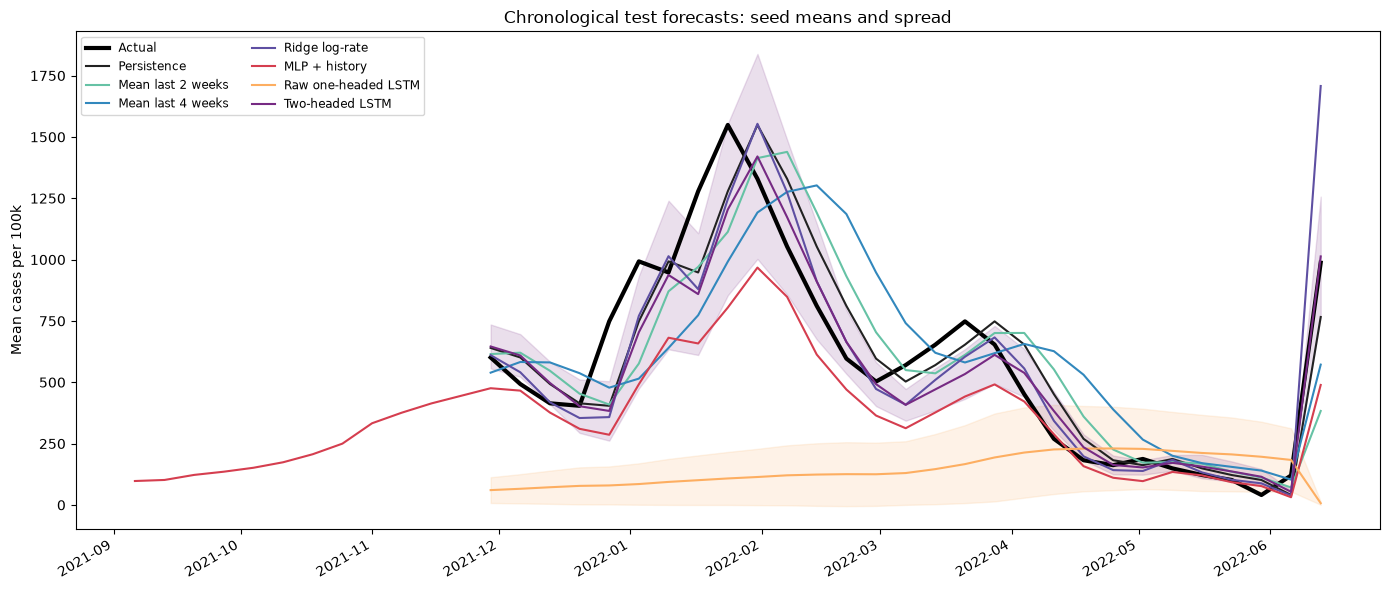

In [12]:
# Compare baselines and neural models on the same chronological test period.
mlp_df = prepare_mlp_frame(final_df, MODEL_COUNTRIES)
_, mlp_history_predictions, mlp_history_metrics = run_mlp_model(mlp_df, CUTOFF, include_history=True, include_deaths=True)
lstm_df = prepare_frame(final_df, MODEL_COUNTRIES)
lstm_train, lstm_test = split_by_time(lstm_df, CUTOFF)

raw_prep = prepare_lstm_data(lstm_train, lstm_test, LOOKBACK, True, True)
full_lstm_df = pd.concat([lstm_train, lstm_test], ignore_index=True)
baseline_predictions = make_baseline_predictions(full_lstm_df, raw_prep["meta_test"], CUTOFF)
persistence_mae = float(np.mean(np.abs(baseline_predictions["Persistence"] - raw_prep["meta_test"]["curr"].to_numpy(float))))
baseline_rows = [score_rate_forecast(name, values, raw_prep["meta_test"], persistence_mae)
                 for name, values in baseline_predictions.items()]

mlp_meta = mlp_history_predictions.merge(
    mlp_df[["Country", "week", "population", "cases_per_100k_lag1"]],
    on=["Country", "week"], how="left"
)
mlp_meta = mlp_meta.rename(columns={"weekly_count": "actual_count"})
mlp_meta["curr"] = mlp_meta["actual_count"] / mlp_meta["population"] * PER_CAPITA_SCALE
mlp_meta["prev"] = mlp_meta["cases_per_100k_lag1"]
mlp_score_meta = mlp_meta[["Country", "week", "prev", "curr"]]
mlp_prediction_rate = mlp_meta["predicted_weekly_count"] / mlp_meta["population"] * PER_CAPITA_SCALE
mlp_rows = [score_rate_forecast("MLP + history", mlp_prediction_rate, mlp_score_meta, persistence_mae)]

raw_seed_predictions, raw_rows = [], []
two_head_seed_predictions, two_head_rows = [], []
two_head_prep = prepare_lstm_data(lstm_train, lstm_test, LOOKBACK, True, True)
for seed in SEEDS:
    raw_fit = fit_raw_lstm(raw_prep, seed)
    raw_prediction = predict_raw_lstm(raw_fit, raw_prep)
    raw_seed_predictions.append(raw_prediction)
    raw_rows.append(score_rate_forecast("Raw one-headed LSTM", raw_prediction, raw_prep["meta_test"], persistence_mae))

    two_head_fit = fit_two_head_lstm(two_head_prep, seed)
    two_head_probability, two_head_prediction = predict_two_head_lstm(two_head_fit, two_head_prep)
    two_head_seed_predictions.append(two_head_prediction)
    two_head_rows.append(score_rate_forecast("Two-headed LSTM", two_head_prediction,
                                              two_head_prep["meta_test"], persistence_mae,
                                              probability=two_head_probability))

raw_seed_predictions = np.asarray(raw_seed_predictions)
two_head_seed_predictions = np.asarray(two_head_seed_predictions)
raw_mean = raw_seed_predictions.mean(axis=0)
raw_spread = raw_seed_predictions.std(axis=0)
two_head_mean = two_head_seed_predictions.mean(axis=0)
two_head_spread = two_head_seed_predictions.std(axis=0)

# Report mean and standard deviation across seeds; baselines have one deterministic run.
def aggregate_seed_scores(rows):
    scores = pd.DataFrame(rows)
    numeric = scores.select_dtypes(include=[np.number]).mean().to_dict()
    numeric["model"] = scores["model"].iloc[0]
    numeric["seed_std_MAE_per_100k"] = float(scores["MAE_per_100k"].std(ddof=0))
    numeric["seed_std_bias_per_100k"] = float(scores["bias_per_100k"].std(ddof=0))
    return numeric

all_results = pd.DataFrame(
    baseline_rows + mlp_rows + [aggregate_seed_scores(raw_rows), aggregate_seed_scores(two_head_rows)]
).set_index("model")
print("All models, cases per 100k:")
print(all_results[["MAE_per_100k", "median_error_per_100k", "bias_per_100k",
                   "MAE_relative_to_persistence", "direction_accuracy", "direction_f1",
                   "direction_auc", "seed_std_MAE_per_100k"]].round(3))

actual_rates = raw_prep["meta_test"][["Country", "week", "curr"]].copy()
plot_predictions = {
    "Persistence": (raw_prep["meta_test"][["Country", "week"]].assign(predicted_rate=baseline_predictions["Persistence"])),
    "Mean last 2 weeks": (raw_prep["meta_test"][["Country", "week"]].assign(predicted_rate=baseline_predictions["Mean last 2 weeks"])),
    "Mean last 4 weeks": (raw_prep["meta_test"][["Country", "week"]].assign(predicted_rate=baseline_predictions["Mean last 4 weeks"])),
    "Ridge log-rate": (raw_prep["meta_test"][["Country", "week"]].assign(predicted_rate=baseline_predictions["Ridge log-rate"])),
    "MLP + history": mlp_meta[["Country", "week"]].assign(predicted_rate=mlp_prediction_rate),
    "Raw one-headed LSTM": raw_prep["meta_test"][["Country", "week"]].assign(predicted_rate=raw_mean),
    "Two-headed LSTM": two_head_prep["meta_test"][["Country", "week"]].assign(predicted_rate=two_head_mean),
}
colors = {"Persistence": "#222222", "Mean last 2 weeks": "#66c2a5", "Mean last 4 weeks": "#3288bd",
          "Ridge log-rate": "#5e4fa2", "MLP + history": "#d53e4f", "Raw one-headed LSTM": "#fdae61",
          "Two-headed LSTM": "#762a83"}

fig, ax = plt.subplots(figsize=(14, 6))
actual_mean = actual_rates.groupby("week")["curr"].mean()
ax.plot(actual_mean.index, actual_mean.values, color="black", linewidth=3, label="Actual")
for label, prediction in plot_predictions.items():
    mean_prediction = prediction.groupby("week")["predicted_rate"].mean()
    ax.plot(mean_prediction.index, mean_prediction.values, color=colors[label], label=label)
if len(raw_mean):
    mean_weeks = raw_prep["meta_test"].groupby("week").size().index
    raw_week_mean = pd.Series(raw_mean).groupby(raw_prep["meta_test"]["week"].to_numpy()).mean()
    raw_week_std = pd.Series(raw_spread).groupby(raw_prep["meta_test"]["week"].to_numpy()).mean()
    two_week_mean = pd.Series(two_head_mean).groupby(two_head_prep["meta_test"]["week"].to_numpy()).mean()
    two_week_std = pd.Series(two_head_spread).groupby(two_head_prep["meta_test"]["week"].to_numpy()).mean()
    ax.fill_between(mean_weeks, raw_week_mean - raw_week_std, raw_week_mean + raw_week_std,
                    color=colors["Raw one-headed LSTM"], alpha=0.15)
    ax.fill_between(mean_weeks, two_week_mean - two_week_std, two_week_mean + two_week_std,
                    color=colors["Two-headed LSTM"], alpha=0.15)
ax.set_ylabel("Mean cases per 100k")
ax.set_title("Chronological test forecasts: seed means and spread")
ax.legend(fontsize="small", ncol=2)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

main = {"two_head": (two_head_prep, two_head_mean)}

## Evaluation interpretation

The direction score must be read together with the label definition. A week is labelled "up" only when its rate is strictly larger than the previous week; ties are currently treated as "down", so the apparent class balance depends on how often rates are unchanged. The two-headed model also converts its probability to a direction at a fixed 0.5 threshold and uses class-balanced training weights. A below-chance AUC can therefore reflect a regime shift, especially the Omicron surge in the test period, rather than evidence that policy measures caused the forecast failure. The full-seed evaluation should report the tie share and compare the pre- and post-December-2021 periods before making a final claim.

## Conclusion

Across the full five-seed, 40-epoch run, the fixed-alpha ridge model is the only evaluated method that beats persistence: MAE 145.664 versus 174.249 cases per 100,000, or 0.836 relative to persistence. The MLP is slightly worse than persistence (ratio 1.061), the two-headed LSTM is worse (1.409; direction AUC 0.463), and the raw one-headed LSTM is much worse (3.198). The two-headed LSTM's seed-to-seed MAE standard deviation is 24.256 cases per 100,000, so its mean is not a single-seed artifact.

The evidence supports using persistence as the null hypothesis and testing a simple lagged-log-rate ridge model before adding neural complexity. It does not support claims that policy measures cause case changes, or that either neural model is superior on this test period. The remaining evaluation work is to split the test period around the Omicron wave, quantify the magnitude-cap effect, retain training context in test windows, and add a rolling-origin backtest.

### 4a. Main experiment: forecasting forward in time

The comparison uses the same chronological test period for all three retained models. The visual comparison reports per-capita MAE, average forecasts, and country-level absolute errors.


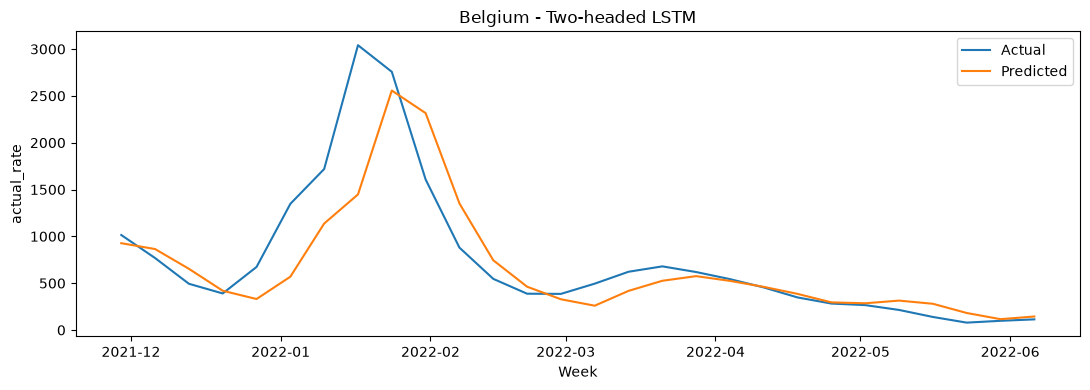

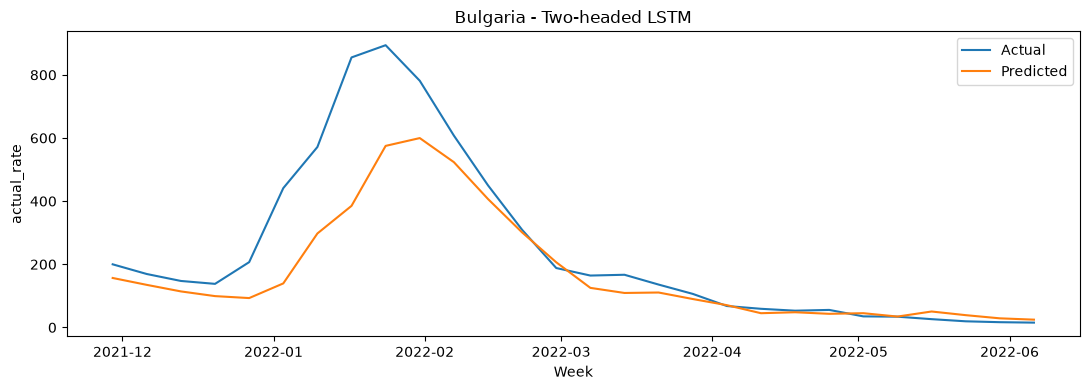

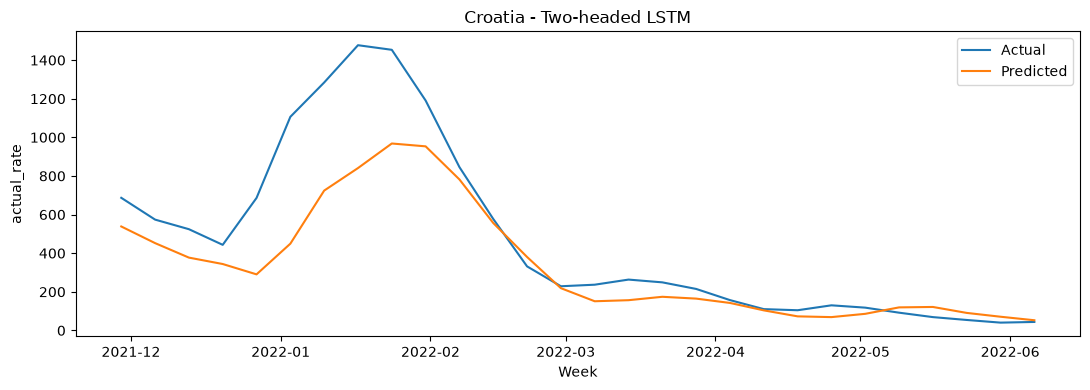

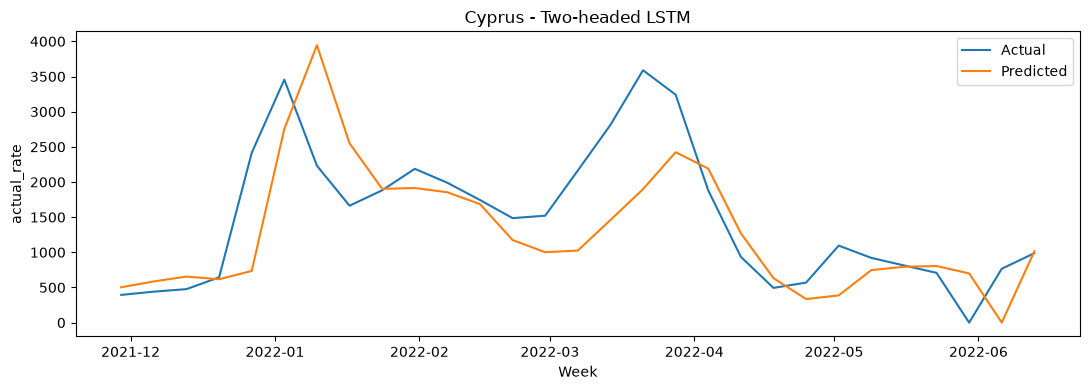

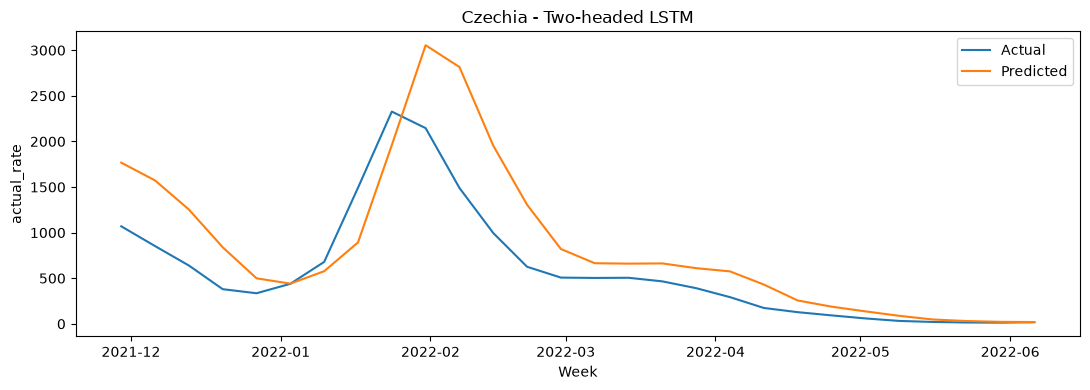

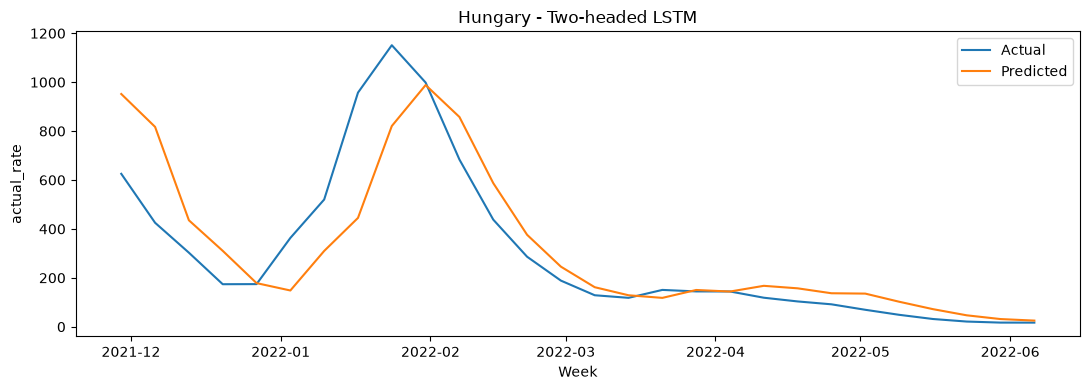

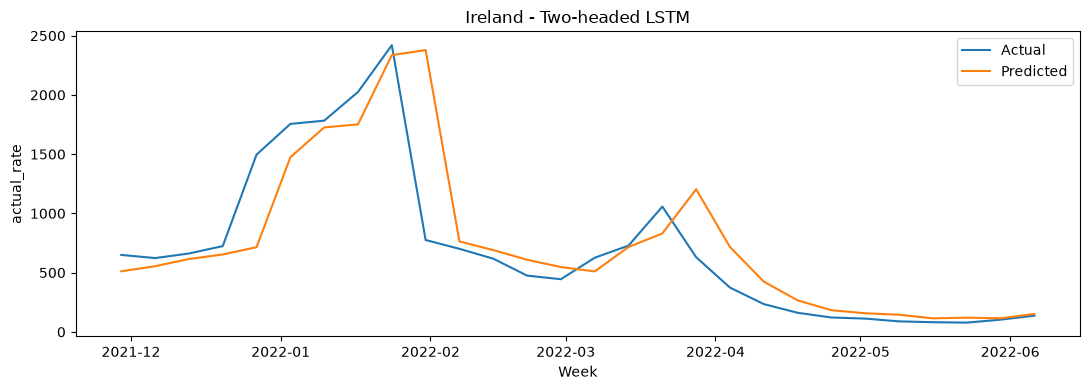

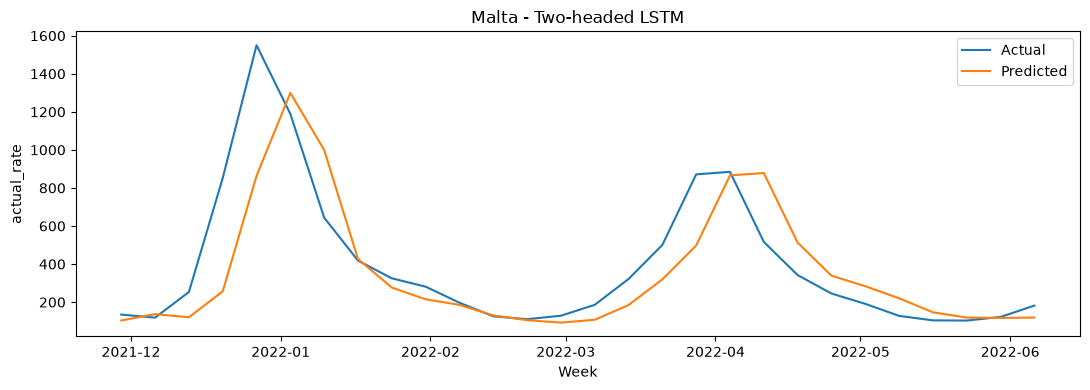

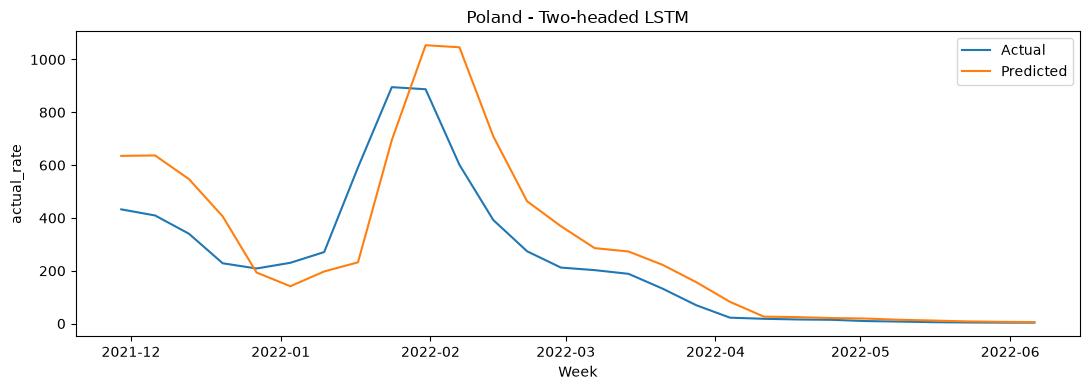

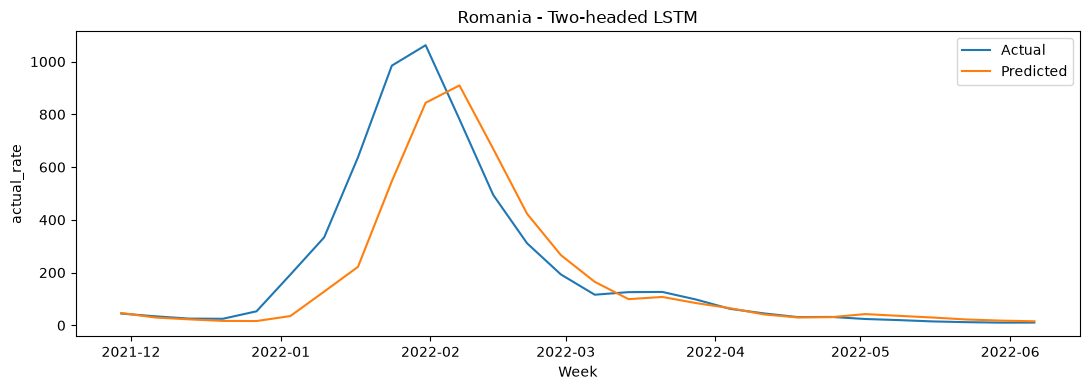

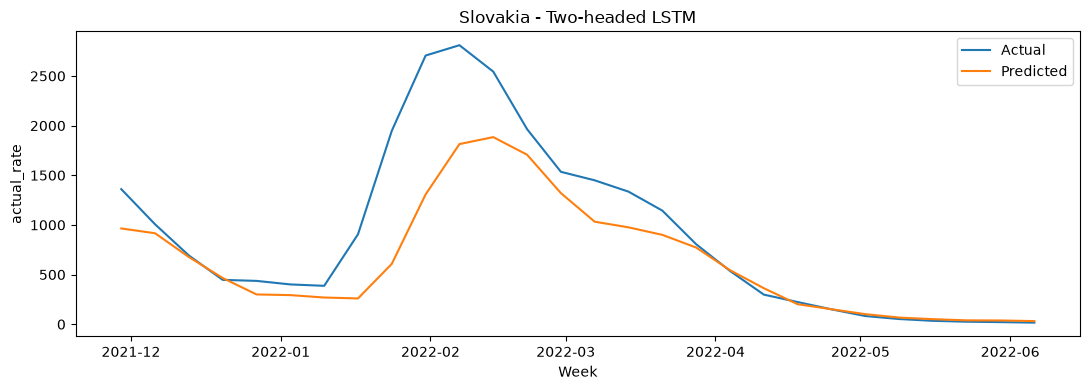

In [13]:
# Plot the retained two-headed LSTM separately for each country.
two_head_prep, two_head_values = main["two_head"]
plot_lstm_predictions(two_head_prep, two_head_values, "Two-headed LSTM")


## Limitations

- **Small data.** A few hundred training sequences from a hand-picked set of countries; results move with the random seed, hence the multi-seed tables. The country list was chosen by hand in the first version - with `MODEL_COUNTRIES = None` all countries in both files are used.
- **Reported cases depend on testing and reporting practice**, which changed over time and differ between countries.
- **Regime change.** A model trained on early waves must forecast later variant waves; the time-split results show how well that works.
- **Policy measures** are recorded as on/off per week. Their effect (if any) cannot be separated from behaviour, seasonality and variants with this set-up, and nothing here estimates a causal effect.
- The descriptive plots are visual only.
